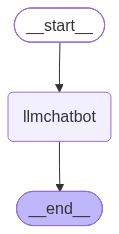

In [61]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START,END
from langgraph.graph.message import add_messages
from langchain_openai import ChatOpenAI
from langchain.chat_models import init_chat_model
from IPython.display import Image, display

llm=ChatOpenAI(model='gpt-3.5-turbo')

class State(TypedDict):
    messages:Annotated[list,add_messages]

def chatbot(state: State):
    return{"messages":[llm.invoke(state["messages"])]}

graph_builder=StateGraph(State)

graph_builder.add_node("llmchatbot", chatbot)
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot", END)
graph=graph_builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))



In [62]:
graph.invoke({'messages':'what is LLM eval'})

{'messages': [HumanMessage(content='what is LLM eval', additional_kwargs={}, response_metadata={}, id='ed313544-6262-4a9e-b2c3-870ab7e31596'),
  AIMessage(content='LLM eval refers to "Late Lock Mode evaluation" in computer science and engineering. It is a technique used for improving the timing closure of a design in Field Programmable Gate Arrays (FPGAs). Late Lock Mode evaluation allows for delayed evaluation of the design to reduce timing violations and improve performance. This technique is commonly used in FPGA synthesis tools to optimize the timing of the design during the implementation process.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 81, 'prompt_tokens': 12, 'total_tokens': 93, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider'

In [63]:
for event in graph.stream({'messages':'what are Machine learning theorems?'}):
    for value in event.values():
        print(value['messages'][-1].content)

Machine learning theorems are mathematical principles or results that describe the theoretical properties and behavior of machine learning algorithms. These theorems provide insights into the assumptions, limitations, convergence rates, and generalization performance of different machine learning models. Some common machine learning theorems include the bias-variance trade-off, the universal approximation theorem, and the generalization error bounds theorem. These theorems are important for understanding how machine learning algorithms work and for making informed decisions about model selection, hyperparameter tuning, and algorithm design.


In [64]:
from langchain_tavily import TavilySearch
tools=TavilySearch(max_results=1)
tools.invoke("what is the live cricket match score between India vs NZ")

{'query': 'what is the live cricket match score between India vs NZ',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://sports.ndtv.com/cricket/ind-vs-nz-scorecard-live-cricket-score-icc-cricket-world-cup-2019-1st-semi-final-innz07092019186722',
   'title': 'IND:221/10 (49.3) | Live Cricket Score | IND vs NZ | | Cricket Scoreboard – NDTV Sports',
   'content': 'India vs New Zealand Scorecard\n\nShare\n\n - Live Cricket Score - IND vs NZ -  - Cricket Scoreboard – NDTV Sports)\n\n - Live Cricket Score - IND vs NZ -  - Cricket Scoreboard – NDTV Sports)\n\nMatch Ended\n\n1st Semi Final, Old Trafford, Manchester , Jul 09, 2019\n\nIndia India\n\n221  (49.3/50)\n\nNew Zealand New Zealand\n\n239/8  (50.0/50)\n\nNew Zealand beat India by 18 runs\n\n% Chance to Win\n\nIND\n\nNZ\n\nInn Break\n\n \n Player of the Match\n\n  Matt Henry\n\n  1(2)&3/37(10)\n\nAdvertisement  ;)\n IND 221/10 (49.3);) [...] Match Info\n\n Venue Old Trafford, Manchester\n Weather

In [65]:
def add(a:int, b:int) ->int:
    """Multiple a and b
    Args:
    a(int): first integer
    b(int): _description_
    Returns:
        int: output int
    """

In [66]:
tools = [tools, add]

llm_with_tool=llm.bind_tools(tools)
llm_with_tool

_ChatModelBinding(bound=ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.6.12', 'langchain': '1.3.14', 'langchain-openai': '1.4.1'}}, profile={'name': 'GPT-3.5-turbo', 'release_date': '2023-03-01', 'last_updated': '2023-11-06', 'open_weights': False, 'max_input_tokens': 16385, 'max_output_tokens': 4096, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': False, 'structured_output': False, 'attachment': False, 'temperature': True, 'image_url_inputs': False, 'pdf_inputs': False, 'pdf_tool_message': False, 'image_tool_message': False, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x00000246FA993F80>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x00000246FA9909B0>, root_client=<openai.Op

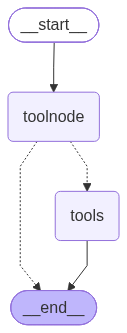

In [67]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode,tools_condition
#Node defination
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state['messages'])]}

#Graph
builder = StateGraph(State)
builder.add_node("toolnode", tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START,"toolnode")
builder.add_conditional_edges("toolnode",tools_condition)
builder.add_edge("tools",END)
graph=builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))



In [68]:
response=graph.invoke({"messages":"Please tell me ongoing Live T20 cricket match score between India vs NZ t20 match"})

In [69]:
response['messages'][-1].content

'{"query": "live India vs NZ T20 match score", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://hindi.moneycontrol.com/sports/cricket/ind-vs-nz-match-live-score-updates-india-vs-new-zealand-3rd-t20-match-at-guwahati-liveblog-2350011.html", "title": "IND vs NZ Highlights: अभिषेक-सूर्या के तूफान में उड़ी कीवी टीम, 10 ओवर में चेज किया 154 रन - ind vs nz match live score updates india vs new zealand 3rd t20 match at guwahati | Moneycontrol Hindi", "score": 0.9801673, "content": "JANUARY 25, 2026 / 9:23 PM IST\\n\\nIndia vs New Zealand Match Live Score: अभिषेक की ताबड़तोड़ फिफ्टी\\n\\nन्यूजीलैंड के खिलाफ तीसरे टी20 में अभिषेक शर्मा ने 14 गेंदों में तूफानी फिफ्टी लगाई। अपनी पारी के दौरान अभिषेक ने 4 छक्का और 5 चौका लगाया है। अभिषेक शर्मा 51 रन बनाकर खेल रहे हैं वहीं सूर्यकुमार यादव 13 रन बनाकर खेल रहे हैं। 6 ओवर के बाद भारत का स्कोर 2 विकेट के नुकसान पर 94 रन है।\\n\\nJANUARY 25, 2026 / 9:17 PM IST\\n\\nIND vs NZ Match Live Score: भारत का स्कोर 72/2", "

In [70]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Please tell me ongoing Live T20 cricket match score between India vs NZ t20 match
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_abE4oO097qjkNPhwTDGB95BK)
 Call ID: call_abE4oO097qjkNPhwTDGB95BK
  Args:
    query: live India vs NZ T20 match score
    search_depth: fast
================================= Tool Message =================================
Name: tavily_search

{"query": "live India vs NZ T20 match score", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://hindi.moneycontrol.com/sports/cricket/ind-vs-nz-match-live-score-updates-india-vs-new-zealand-3rd-t20-match-at-guwahati-liveblog-2350011.html", "title": "IND vs NZ Highlights: अभिषेक-सूर्या के तूफान में उड़ी कीवी टीम, 10 ओवर में चेज किया 154 रन - ind vs nz match live score updates india vs new zealand 3rd t20 match at guwahati | Moneycontrol 

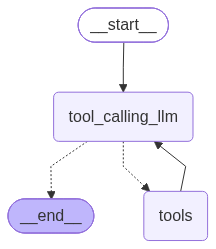

In [71]:
#REACT

from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_openai import ChatOpenAI
#Node defination

def tool_calling_llm(state:State):
    return {'messages':[llm_with_tool.invoke(state['messages'])]}
#Graph
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",tools_condition)
builder.add_edge("tools","tool_calling_llm")

graph=builder.compile()
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


In [72]:
response=graph.invoke({'messages':"Give me latest news on cricket game and using another tool please let me know what is 2+4?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me latest news on cricket game and using another tool please let me know what is 2+4?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_SlV0GRR7ihcE0EVifnwXeH3N)
 Call ID: call_SlV0GRR7ihcE0EVifnwXeH3N
  Args:
    query: latest news on cricket game
    topic: news
  add (call_29vuDmdbtsekBAxDRTI7kOnq)
 Call ID: call_29vuDmdbtsekBAxDRTI7kOnq
  Args:
    a: 2
    b: 4
================================= Tool Message =================================
Name: tavily_search

{"query": "latest news on cricket game", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://apnews.com/article/los-angeles-knight-riders-cricket-field-65b7f94726a6b33d16ca675aa0f9fdc9", "title": "First cricket game in new Los Angeles stadium builds Olympic buzz | AP News", "content": "ByDEEPA BHARATH\n\nUpdated [hour]:[minute] [AMPM] [tim

In [73]:
from langgraph.graph import StateGraph, START,END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver

def tool_calling_llm(state:State):
    return{"messages":[llm_with_tool.invoke(state['messages'])]}
#Graph

builder=StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",tools_condition)
builder.add_edge("tools","tool_calling_llm")

memory=MemorySaver()
graph=builder.compile(checkpointer=memory)

config={'configurable':{"thread_id":"1"}}

result=graph.invoke({'messages':"Hi my name is akash and i like cricket and also i play cricket, i worked as a Problem manager in ATOS company and i live in Maharastra state"},config)



In [74]:
result

{'messages': [HumanMessage(content='Hi my name is akash and i like cricket and also i play cricket, i worked as a Problem manager in ATOS company and i live in Maharastra state', additional_kwargs={}, response_metadata={}, id='3000b4a3-8153-45e1-866c-4880fe448d5d'),
  AIMessage(content="Hello Akash! It's great to hear that you enjoy cricket and play the sport! Working as a Problem Manager at ATOS sounds interesting. Maharashtra is a wonderful state with a rich cultural heritage and diverse attractions. Is there anything specific you'd like to know or discuss? Feel free to ask any questions or share more about your interests!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 69, 'prompt_tokens': 1334, 'total_tokens': 1403, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tok

In [75]:
que=graph.invoke({'messages':"which company i am currently working?"},config)
print(que['messages'][-1].content)

You mentioned that you currently work as a Problem Manager in ATOS company. It's great to know about your role there. If you have any specific questions or topics you'd like to explore further, feel free to let me know!


In [76]:
config = {'configurable':{'thread_id':'3'}}
for chunk in graph.stream({'messages':'hi my name is akash and i like cricket'},config):
    print(chunk)

{'tool_calling_llm': {'messages': [AIMessage(content="Hello Akash! It's great to meet you. Cricket is a fantastic sport! If you have any questions or need information related to cricket or anything else, feel free to ask!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 38, 'prompt_tokens': 1310, 'total_tokens': 1348, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-3.5-turbo-0125', 'system_fingerprint': None, 'id': 'chatcmpl-EblkQqRQEWFIMGvRHHfzBE2inwnxc', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1637b-483a-773b-9a99-d37bcb42ac2e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1310, 'output_tokens': 38, 'total_tokens': 1348, 'input_token_deta

In [77]:
async for event in graph.astream_events({"messages":'hi my name is akash and i like cricket'}, config, version='v2'):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': 'hi my name is akash and i like cricket'}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a1637b-4bf7-72a6-a1a2-aa9306b84976', 'metadata': {'thread_id': '3', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='hi my name is akash and i like cricket', additional_kwargs={}, response_metadata={}, id='fd8d51ca-b974-4ced-bb5a-9c16f28cd0ff'), AIMessage(content="Hello Akash! It's great to meet you. Cricket is a fantastic sport! If you have any questions or need information related to cricket or anything else, feel free to ask!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 38, 'prompt_tokens': 1310, 'total_tokens': 1348, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_

In [78]:
import os
from langchain.chat_models import init_chat_model
llm=init_chat_model("openai:gpt-3.5-turbo")
llm

ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.6.12', 'langchain': '1.3.14', 'langchain-openai': '1.4.1'}}, profile={'name': 'GPT-3.5-turbo', 'release_date': '2023-03-01', 'last_updated': '2023-11-06', 'open_weights': False, 'max_input_tokens': 16385, 'max_output_tokens': 4096, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': False, 'structured_output': False, 'attachment': False, 'temperature': True, 'image_url_inputs': False, 'pdf_inputs': False, 'pdf_tool_message': False, 'image_tool_message': False, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x00000246F7797D70>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x00000246F7790CB0>, root_client=<openai.OpenAI object at 0x0000024

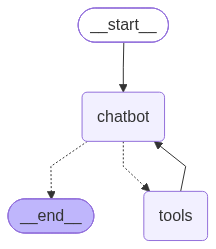

In [79]:
from typing import Annotated
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from typing_extensions import TypedDict

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import Command, interrupt
from IPython.display import Image, display

class State(TypedDict):
    messages: Annotated[list, add_messages]

graph_builder=StateGraph(State)

@tool 
def human_assistance(query:str) -> str:
    """Request assistance from a human"""
    human_response=interrupt({"query":query})
    return human_response['data']

tool=TavilySearch(max_results=2)
tools=[tool,human_assistance]
llm_with_tool=llm.bind_tools(tools)

def chatbot(state:State):
    message=llm_with_tool.invoke(state['messages'])
    return{"messages":[message]}

graph_builder.add_node("chatbot",chatbot)
tool_node=ToolNode(tools=tools)
graph_builder.add_node("tools",tool_node)
graph_builder.add_conditional_edges("chatbot",tools_condition)
graph_builder.add_edge(START,"chatbot")
graph_builder.add_edge("tools","chatbot")

memory=MemorySaver()
graph=graph_builder.compile(checkpointer=memory)

display(Image(graph.get_graph().draw_mermaid_png()))


In [80]:
user_input = "I need some assistance for building an AI agent. Could you request assistance for me?"
config={'configurable':{'thread_id':"1"}}

events=graph.stream({'messages':user_input},config, stream_mode="values")
for event in events:
    if 'messages' in event:
        event['messages'][-1].pretty_print()

================================ Human Message =================================

I need some assistance for building an AI agent. Could you request assistance for me?
================================== Ai Message ==================================
Tool Calls:
  human_assistance (call_0yfhdWfmp0wqZQxIdi5Xkmep)
 Call ID: call_0yfhdWfmp0wqZQxIdi5Xkmep
  Args:
    query: I need assistance for building an AI agent
================================== Ai Message ==================================
Tool Calls:
  human_assistance (call_0yfhdWfmp0wqZQxIdi5Xkmep)
 Call ID: call_0yfhdWfmp0wqZQxIdi5Xkmep
  Args:
    query: I need assistance for building an AI agent


In [81]:

human_response = ("we are here to help! we did recommend you check out Langgraph to build your agent. its much more reliable and extensible than single autonomous system")
human_command=Command(resume={'data':human_response})

events=graph.stream(human_command, config, stream_mode="values")

for event in events:
    if "messages" in event:
        event['messages'][-1].pretty_print()

================================== Ai Message ==================================
Tool Calls:
  human_assistance (call_0yfhdWfmp0wqZQxIdi5Xkmep)
 Call ID: call_0yfhdWfmp0wqZQxIdi5Xkmep
  Args:
    query: I need assistance for building an AI agent
================================= Tool Message =================================
Name: human_assistance

we are here to help! we did recommend you check out Langgraph to build your agent. its much more reliable and extensible than single autonomous system
================================== Ai Message ==================================

I have requested assistance for you to get help with building an AI agent. If you need further guidance, feel free to ask!
